In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import load_npz

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score

import pickle

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving X_test_tfidf.npz to X_test_tfidf.npz
Saving X_train_tfidf.npz to X_train_tfidf.npz
Saving y_test.csv to y_test.csv
Saving y_train.csv to y_train.csv


In [4]:
X_train_tfidf = load_npz("X_train_tfidf.npz")
X_test_tfidf = load_npz("X_test_tfidf.npz")

y_train = pd.read_csv("y_train.csv").iloc[:, 0]
y_test = pd.read_csv("y_test.csv").iloc[:, 0]

print("Data loaded successfully!")

print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Data loaded successfully!
Training Features: (2560, 632)
Testing Features: (640, 632)
Training Labels: (2560,)
Testing Labels: (640,)


In [5]:
print("Training Label Distribution:")
print(y_train.value_counts())

print("\nTesting Label Distribution:")
print(y_test.value_counts())

print("\nTraining Labels:")
print(y_train.unique())

Training Label Distribution:
label
MISINFORMATION    1280
INFORMATION       1280
Name: count, dtype: int64

Testing Label Distribution:
label
INFORMATION       320
MISINFORMATION    320
Name: count, dtype: int64

Training Labels:
['MISINFORMATION' 'INFORMATION']


In [6]:
# Create Logistic Regression Model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train Model
lr_model.fit(X_train_tfidf, y_train)

# Predict Testing Data
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression Training Completed!")

lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

print("Logistic Regression Accuracy:",
      lr_accuracy * 100, "%")

Logistic Regression Training Completed!
Logistic Regression Accuracy: 100.0 %


In [7]:
# Create Naive Bayes Model

nb_model = MultinomialNB()

# Train Model
nb_model.fit(X_train_tfidf, y_train)

# Predict Testing Data
nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes Training Completed!")

nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

print("Naive Bayes Accuracy:",
      nb_accuracy * 100, "%")

Naive Bayes Training Completed!
Naive Bayes Accuracy: 100.0 %


In [8]:
# Create Linear SVM Model

svm_model = LinearSVC(
    random_state=42
)

# Train Model
svm_model.fit(X_train_tfidf, y_train)

# Predict Testing Data
svm_predictions = svm_model.predict(X_test_tfidf)

print("Linear SVM Training Completed!")

svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

print("Linear SVM Accuracy:",
      svm_accuracy * 100, "%")

Linear SVM Training Completed!
Linear SVM Accuracy: 100.0 %


In [9]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy
    ]
})

model_results["Accuracy_Percentage"] = (
    model_results["Accuracy"] * 100
)

display(model_results)

,Model,Accuracy,Accuracy_Percentage
0,Logistic Regression,1.0,100.0
1,Naive Bayes,1.0,100.0
2,Linear SVM,1.0,100.0


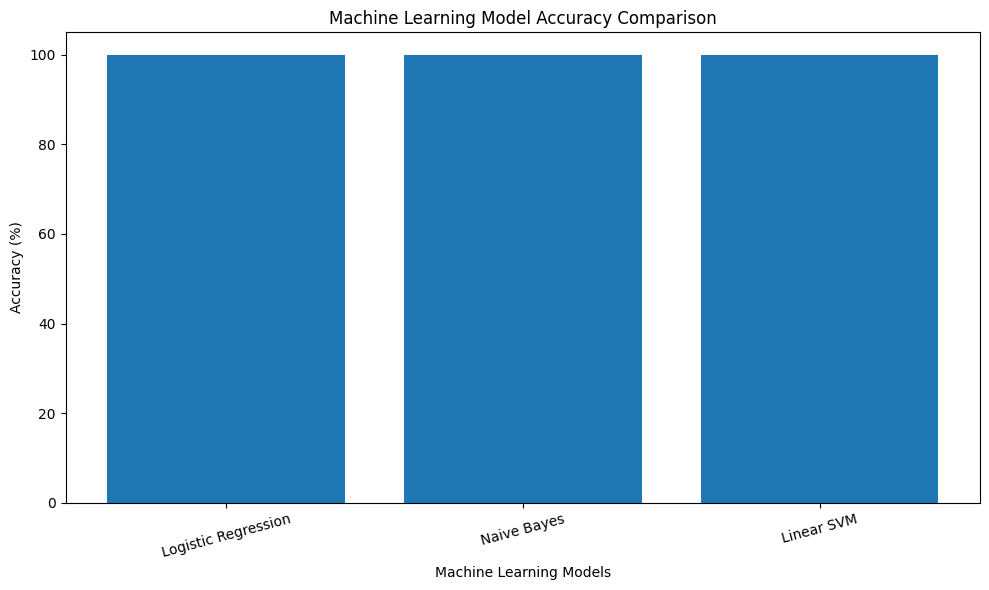

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_results["Model"],
    model_results["Accuracy_Percentage"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [11]:
best_model_row = model_results.loc[
    model_results["Accuracy"].idxmax()
]

print("Best Model:", best_model_row["Model"])

print(
    "Best Accuracy:",
    round(best_model_row["Accuracy_Percentage"], 2),
    "%"
)

Best Model: Logistic Regression
Best Accuracy: 100.0 %


In [12]:
with open(
    "Logistic_Regression_Model.pkl",
    "wb"
) as file:

    pickle.dump(lr_model, file)

print("Logistic Regression Model Saved!")

Logistic Regression Model Saved!


In [13]:
with open(
    "Naive_Bayes_Model.pkl",
    "wb"
) as file:

    pickle.dump(nb_model, file)

print("Naive Bayes Model Saved!")

Naive Bayes Model Saved!


In [14]:
with open(
    "Linear_SVM_Model.pkl",
    "wb"
) as file:

    pickle.dump(svm_model, file)

print("Linear SVM Model Saved!")

Linear SVM Model Saved!


In [15]:
model_results.to_csv(
    "Model_Comparison.csv",
    index=False
)

print("Model Comparison Saved!")

Model Comparison Saved!


In [ ]:
from google.colab import files

files.download("Logistic_Regression_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("Logistic_Regression_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("Naive_Bayes_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
files.download("Linear_SVM_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
files.download("Model_Comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
print("STEP 7: MACHINE LEARNING TRAINING")
print("--------------------------------")

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("Naive Bayes Accuracy:",
      round(nb_accuracy * 100, 2), "%")

print("Linear SVM Accuracy:",
      round(svm_accuracy * 100, 2), "%")

print("--------------------------------")

print("Best Model:", best_model_row["Model"])

print("--------------------------------")

print("STEP 7 COMPLETED SUCCESSFULLY!")

STEP 7: MACHINE LEARNING TRAINING
--------------------------------
Logistic Regression Accuracy: 100.0 %
Naive Bayes Accuracy: 100.0 %
Linear SVM Accuracy: 100.0 %
--------------------------------
Best Model: Logistic Regression
--------------------------------
STEP 7 COMPLETED SUCCESSFULLY!
